# Clustering track: Starbucks menu nutrition

**Problem statement:** group Starbucks menu items into natural clusters based only on their nutritional profile (calories, fats, sugars, protein, caffeine, ...), without using any labels while fitting.

**Algorithms (required):** K-Means and Agglomerative Hierarchical Clustering.
**Metrics (required):** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index.
**Visualisations (required):** Elbow curve, Dendrogram, PCA 2D scatter for every algorithm, t-SNE for at least one.

> Dataset: Starbucks Menu, Kaggle (`starbucks/starbucks-menu`). The ground-truth category (e.g. `beverage_category`) is used **only after fitting** to interpret and sanity-check the clusters.
> Code scaffolding assisted by an AI tool (cite this in the README); all interpretation is the team's own.

In [1]:
import os, re, glob, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
PALETTE = sns.color_palette("colorblind")

## 1. load and audit the data

Put the CSV in the repo's `data/` folder. The default is `starbucks_drinkMenu_expanded.csv`, which has the richest set of nutrition features. If your instructor assigned one of the other files from the Kaggle dataset, change `DATA_FILE`; the rest of the notebook adapts to whatever numeric columns exist.

In [2]:
DATA_FILE = "starbucks_drinkMenu_expanded.csv"

candidates = [f"../data/{DATA_FILE}", f"data/{DATA_FILE}", DATA_FILE,
              f"/kaggle/input/starbucks-menu/{DATA_FILE}"]
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(f"{DATA_FILE} not found. Put it in the data/ folder or edit DATA_FILE.")

for enc in ["utf-8", "utf-16", "latin-1"]:          # the food file in this dataset is UTF-16
    try:
        raw = pd.read_csv(path, encoding=enc)
        break
    except (UnicodeDecodeError, UnicodeError):
        continue
print("loaded:", path)
print("shape :", raw.shape)
display(raw.head())
print("\ndtypes:")
print(raw.dtypes)
print("\nmissing values per column:")
print(raw.isna().sum())
print("\nduplicate rows:", raw.duplicated().sum())

loaded: starbucks_drinkMenu_expanded.csv
shape : (242, 18)


,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75



dtypes:
Beverage_category                str
Beverage                         str
Beverage_prep                    str
Calories                       int64
 Total Fat (g)                   str
Trans Fat (g)                float64
Saturated Fat (g)            float64
 Sodium (mg)                   int64
 Total Carbohydrates (g)       int64
Cholesterol (mg)               int64
 Dietary Fibre (g)             int64
 Sugars (g)                    int64
 Protein (g)                 float64
Vitamin A (% DV)                 str
Vitamin C (% DV)                 str
 Calcium (% DV)                  str
Iron (% DV)                      str
Caffeine (mg)                    str
dtype: object

missing values per column:
Beverage_category            0
Beverage                     0
Beverage_prep                0
Calories                     0
 Total Fat (g)               0
Trans Fat (g)                0
Saturated Fat (g)            0
 Sodium (mg)                 0
 Total Carbohydrates (g)     0
Chol

## 2. cleaning

Steps: tidy column names (the raw file has stray spaces and units), convert numeric columns that were read as text (e.g. `"10%"`, `"Varies"`, `"-"`), repair a data-entry typo, check the column labels (section 2.1), and impute the remaining NaNs with the median.

In [3]:
def tidy_name(c):
    c = re.sub(r"\(.*?\)", "", str(c))                 # drop units like (g), (mg), (% DV)
    return re.sub(r"[^a-z0-9]+", "_", c.strip().lower()).strip("_")

df = raw.copy()
df.columns = [tidy_name(c) for c in df.columns]

numeric_cols, text_cols = [], []
for col in df.columns:
    if col.startswith("unnamed"):
        text_cols.append(col)                            # index / name column, never a feature
        continue
    s = df[col].astype(str).str.replace("%", "", regex=False).str.strip()
    s = s.str.replace(r"^(\d+)\s+(\d+)$", r"\1.\2", regex=True)   # typo such as "3 2" -> "3.2"
    converted = pd.to_numeric(s, errors="coerce")        # "Varies", "-" become NaN
    if converted.notna().mean() >= 0.6:                  # mostly numeric -> feature
        df[col] = converted
        numeric_cols.append(col)
    else:
        text_cols.append(col)

n_missing = df[numeric_cols].isna().sum()
print("numeric features:", numeric_cols)
print("text columns    :", text_cols)
print("\nmissing after type conversion:")
print(n_missing[n_missing > 0] if n_missing.sum() else "none")

numeric features: ['calories', 'total_fat', 'trans_fat', 'saturated_fat', 'sodium', 'total_carbohydrates', 'cholesterol', 'dietary_fibre', 'sugars', 'protein', 'vitamin_a', 'vitamin_c', 'calcium', 'iron', 'caffeine']
text columns    : ['beverage_category', 'beverage', 'beverage_prep']

missing after type conversion:
caffeine    23
dtype: int64


### 2.1 sanity check of the column labels

In `starbucks_drinkMenu_expanded.csv` the header order does not match the data order, a known problem with this Kaggle file. Physical rules expose it: sugars can never exceed total carbohydrates, and trans fat can never exceed saturated fat. If those rules fail under the given labels, the labels are shifted and are corrected below.

In [4]:
need = {"trans_fat", "saturated_fat", "sodium", "total_carbohydrates", "cholesterol", "sugars"}
if need <= set(df.columns):
    bad_sugar = int((df["sugars"] > df["total_carbohydrates"]).sum())
    bad_fat = int((df["trans_fat"] > df["saturated_fat"]).sum())
    print(f"as labelled : sugars > total_carbohydrates in {bad_sugar} rows, trans_fat > saturated_fat in {bad_fat} rows (both impossible)")

    if bad_sugar > 0 or bad_fat > 0:
        # the data columns are in the order: saturated fat, trans fat, cholesterol, sodium, total carbs
        df = df.rename(columns={"trans_fat": "saturated_fat", "saturated_fat": "trans_fat",
                                "sodium": "cholesterol", "total_carbohydrates": "sodium",
                                "cholesterol": "total_carbohydrates"})
        bad_sugar = int((df["sugars"] > df["total_carbohydrates"]).sum())
        bad_fat = int((df["trans_fat"] > df["saturated_fat"]).sum())
        atwater = 9 * df["total_fat"] + 4 * df["total_carbohydrates"] + 4 * df["protein"]
        print(f"after fixing: sugars > carbs in {bad_sugar} rows, trans > saturated in {bad_fat} rows")
        print(f"calories vs (9*fat + 4*carbs + 4*protein) correlation: {np.corrcoef(df['calories'], atwater)[0, 1]:.3f}")
else:
    print("expanded-file columns not present; no label check needed for this file")

as labelled : sugars > total_carbohydrates in 13 rows, trans_fat > saturated_fat in 209 rows (both impossible)
after fixing: sugars > carbs in 0 rows, trans > saturated in 0 rows
calories vs (9*fat + 4*carbs + 4*protein) correlation: 0.996


**note for the report:** *(write your own sentence: the headers were mislabelled in the source file, you detected it with the sugars <= carbs rule and corrected it)*

In [5]:
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())   # global median: robust to skew, and uses no labels

# drop constant columns: they carry no information for clustering
const = [c for c in numeric_cols if df[c].nunique() <= 1]
numeric_cols = [c for c in numeric_cols if c not in const]
print("dropped constant columns:", const or "none")

# post-hoc label column (NEVER used for fitting)
LABEL_COL = next((c for c in ["beverage_category", "type"] if c in df.columns), None)
print("label column for post-hoc validation:", LABEL_COL)
display(df[numeric_cols].describe().T.round(2))

dropped constant columns: none
label column for post-hoc validation: beverage_category


,count,mean,std,min,25%,50%,75%,max
calories,242.0,193.87,102.86,0.0,120.0,185.0,260.00,510.0
total_fat,242.0,2.90,2.94,0.0,0.2,2.5,4.50,15.0
trans_fat,242.0,0.04,0.07,0.0,0.0,0.0,0.10,0.3
saturated_fat,242.0,1.31,1.64,0.0,0.1,0.5,2.00,9.0
sodium,242.0,128.88,82.30,0.0,70.0,125.0,170.00,340.0
total_carbohydrates,242.0,35.99,20.80,0.0,21.0,34.0,50.75,90.0
cholesterol,242.0,6.36,8.63,0.0,0.0,5.0,10.00,40.0
dietary_fibre,242.0,0.81,1.45,0.0,0.0,0.0,1.00,8.0
sugars,242.0,32.96,19.73,0.0,18.0,32.0,43.75,84.0
protein,242.0,6.98,4.87,0.0,3.0,6.0,10.00,20.0


### outlier check

Outliers are counted with the IQR rule. For a menu, extreme values (very high calories or caffeine) are real products, not errors, so they are **kept**; standard scaling is applied before clustering.

In [6]:
q1, q3 = df[numeric_cols].quantile(0.25), df[numeric_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[numeric_cols] < q1 - 1.5 * iqr) | (df[numeric_cols] > q3 + 1.5 * iqr)).sum()
display(outliers.rename("IQR outliers").to_frame().T)

,calories,total_fat,trans_fat,saturated_fat,sodium,total_carbohydrates,cholesterol,dietary_fibre,sugars,protein,vitamin_a,vitamin_c,calcium,iron,caffeine
IQR outliers,1,5,4,12,4,0,9,16,3,0,3,54,0,17,6


**cleaning notes:** *(write your own: what was missing, how you handled it, why outliers were kept)*

## 3. exploratory data analysis

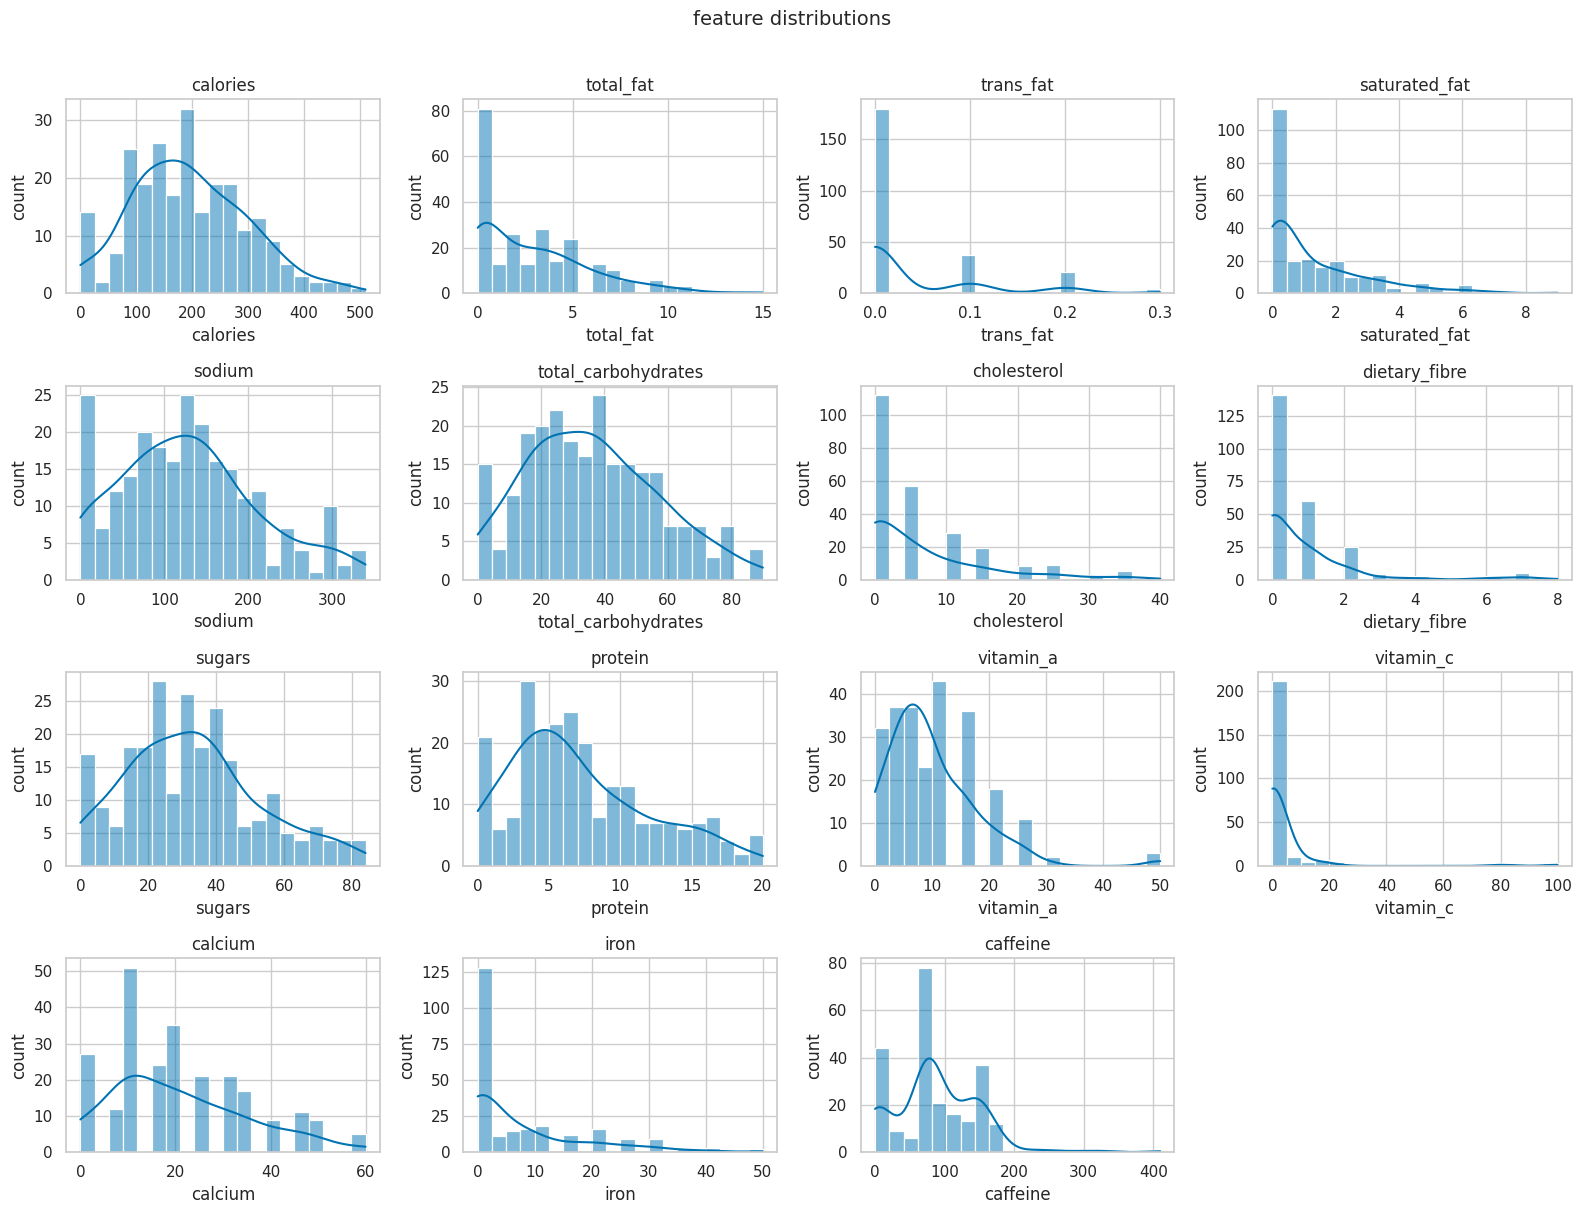

In [7]:
# distribution of every feature
ncols = 4
nrows = math.ceil(len(numeric_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(df[col], bins=20, kde=True, color=PALETTE[0], ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("count")
for ax in axes.ravel()[len(numeric_cols):]:
    ax.axis("off")
fig.suptitle("feature distributions", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

**observation:** *(write your own: skewness, zero-heavy features, anything unusual)*

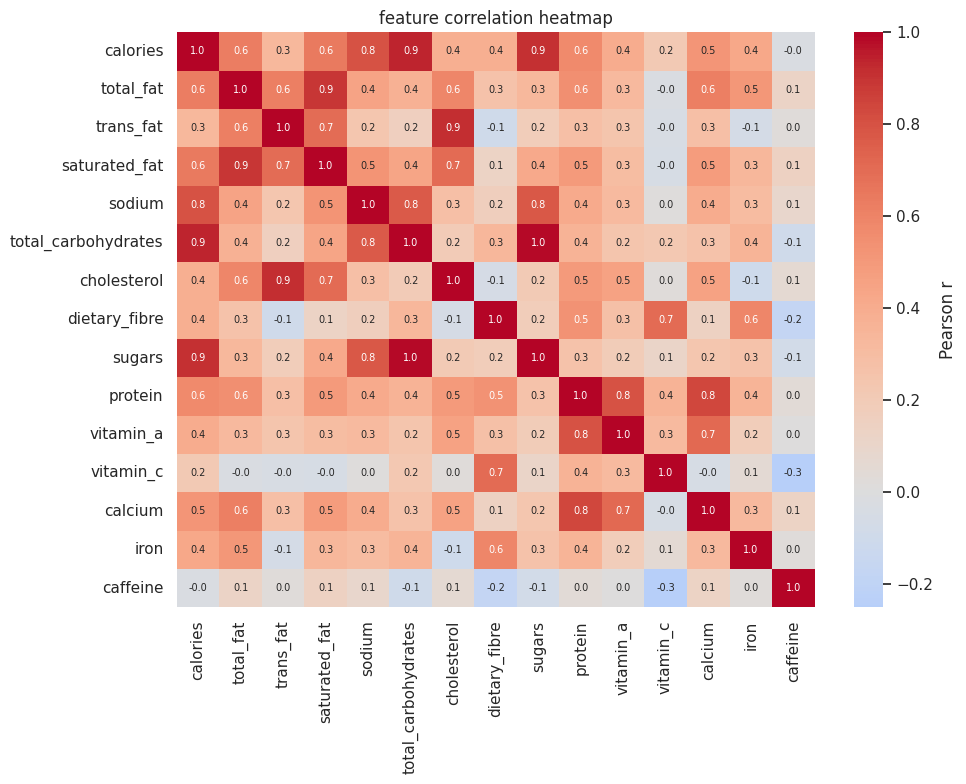

In [8]:
# correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".1f", cmap="coolwarm", center=0,
            annot_kws={"size": 7}, cbar_kws={"label": "Pearson r"})
plt.title("feature correlation heatmap")
plt.tight_layout()
plt.show()

**observation:** *(write your own: which features move together, and what that means for clustering)*

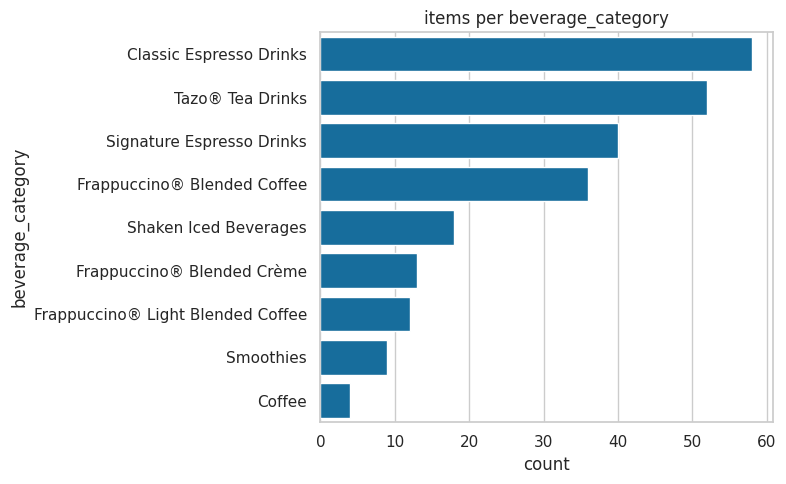

In [9]:
# category distribution (only used to understand the data, not for fitting)
if LABEL_COL:
    plt.figure(figsize=(8, 5))
    order = df[LABEL_COL].value_counts().index
    sns.countplot(y=df[LABEL_COL], order=order, color=PALETTE[0])
    plt.title(f"items per {LABEL_COL}")
    plt.xlabel("count")
    plt.ylabel(LABEL_COL)
    plt.tight_layout()
    plt.show()

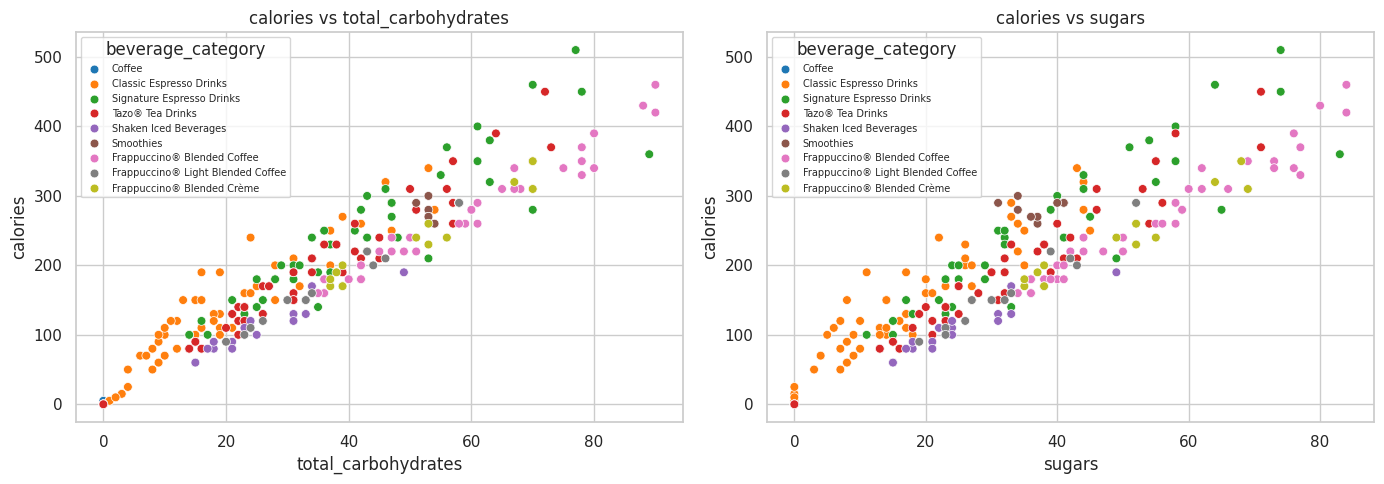

In [10]:
# two scatter plots: calories against its two most correlated features
base = "calories" if "calories" in numeric_cols else numeric_cols[0]
partners = df[numeric_cols].corr()[base].drop(base).abs().sort_values(ascending=False).index[:2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, partner in zip(axes, partners):
    sns.scatterplot(data=df, x=partner, y=base, hue=LABEL_COL, palette="tab10", s=40, ax=ax)
    ax.set_title(f"{base} vs {partner}")
    ax.set_xlabel(partner)
    ax.set_ylabel(base)
    if LABEL_COL:
        ax.legend(fontsize=7, title=LABEL_COL, loc="best")
plt.tight_layout()
plt.show()

**observation:** *(write your own: do natural groups already show up visually?)*

## 4. scaling and PCA projection

K-Means and hierarchical clustering are distance-based, so features are standardised (mean 0, std 1); otherwise sodium (mg) would dominate fat (g). There is no train/test split in clustering, so scaling the full data is not leakage. PCA to 2 components is used only for plotting.

In [11]:
X = df[numeric_cols].values
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_
print(f"PC1 explains {evr[0]:.1%}, PC2 explains {evr[1]:.1%} (total {evr.sum():.1%})")

loadings = pd.DataFrame(pca.components_.T, index=numeric_cols, columns=["PC1", "PC2"]).round(2)
display(loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index))

PC1 explains 42.0%, PC2 explains 16.5% (total 58.5%)


,PC1,PC2
calories,0.36,-0.16
total_fat,0.32,0.19
saturated_fat,0.32,0.24
protein,0.31,-0.02
total_carbohydrates,0.30,-0.28
sodium,0.30,-0.10
sugars,0.28,-0.23
calcium,0.28,0.14
cholesterol,0.25,0.41
vitamin_a,0.24,0.03


## 5. K-Means

### 5.1 choosing k: elbow curve and silhouette

,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,1,3630.000,NaN,NaN,NaN
1,2,2625.903,0.311,1.527,91.772
2,3,2237.031,0.273,1.579,74.411
3,4,1898.075,0.274,1.309,72.389
4,5,1657.616,0.285,1.274,70.501
5,6,1472.603,0.222,1.332,69.149
6,7,1353.130,0.222,1.264,65.905
7,8,1234.182,0.242,1.239,64.892
8,9,1140.699,0.232,1.216,63.558
9,10,1081.084,0.222,1.282,60.777


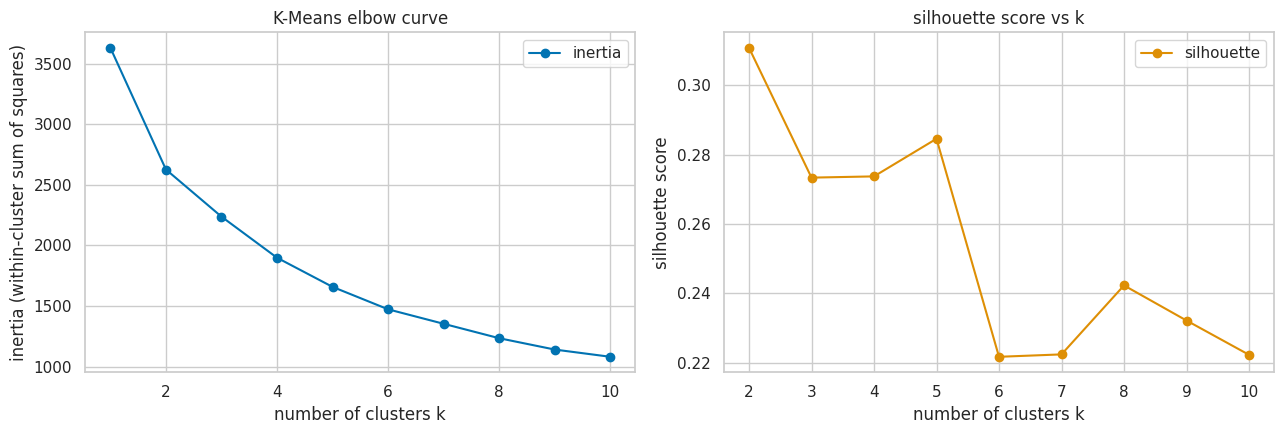

In [12]:
def cluster_metrics(X_, labels_):
    return {"Silhouette": silhouette_score(X_, labels_),
            "Davies-Bouldin": davies_bouldin_score(X_, labels_),
            "Calinski-Harabasz": calinski_harabasz_score(X_, labels_)}

k_rows = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)
    row = {"k": k, "Inertia": km.inertia_}
    if k >= 2:
        row.update(cluster_metrics(X_scaled, km.labels_))
    k_rows.append(row)
k_table = pd.DataFrame(k_rows)
display(k_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_table["k"], k_table["Inertia"], "o-", color=PALETTE[0], label="inertia")
axes[0].set_title("K-Means elbow curve")
axes[0].set_xlabel("number of clusters k")
axes[0].set_ylabel("inertia (within-cluster sum of squares)")
axes[0].legend()

sil = k_table.dropna(subset=["Silhouette"])
axes[1].plot(sil["k"], sil["Silhouette"], "o-", color=PALETTE[1], label="silhouette")
axes[1].set_title("silhouette score vs k")
axes[1].set_xlabel("number of clusters k")
axes[1].set_ylabel("silhouette score")
axes[1].legend()
plt.tight_layout()
plt.show()

**choice of k:** *(write your own: where the elbow bends, what the silhouette says, and why you picked k)*

By default the code below takes the k with the best silhouette among k >= 3 (k = 2 often wins trivially by splitting into two big blobs). Set `K_CHOSEN` yourself if the elbow suggests a different value.

In [13]:
K_CHOSEN = None   # e.g. K_CHOSEN = 4 to override
if K_CHOSEN is None:
    K_CHOSEN = int(sil[sil["k"] >= 3].sort_values("Silhouette").iloc[-1]["k"])
print("k used for both algorithms:", K_CHOSEN)

kmeans = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=SEED).fit(X_scaled)
km_labels = kmeans.labels_
print("K-Means cluster sizes:", {int(k): int(v) for k, v in pd.Series(km_labels).value_counts().sort_index().items()})

k used for both algorithms: 5
K-Means cluster sizes: {0: 120, 1: 43, 2: 6, 3: 31, 4: 42}


## 6. agglomerative hierarchical clustering

### 6.1 dendrograms for four linkage strategies

The dashed line marks the cut that gives `K_CHOSEN` clusters (the same k as K-Means, so the two algorithms are compared fairly).

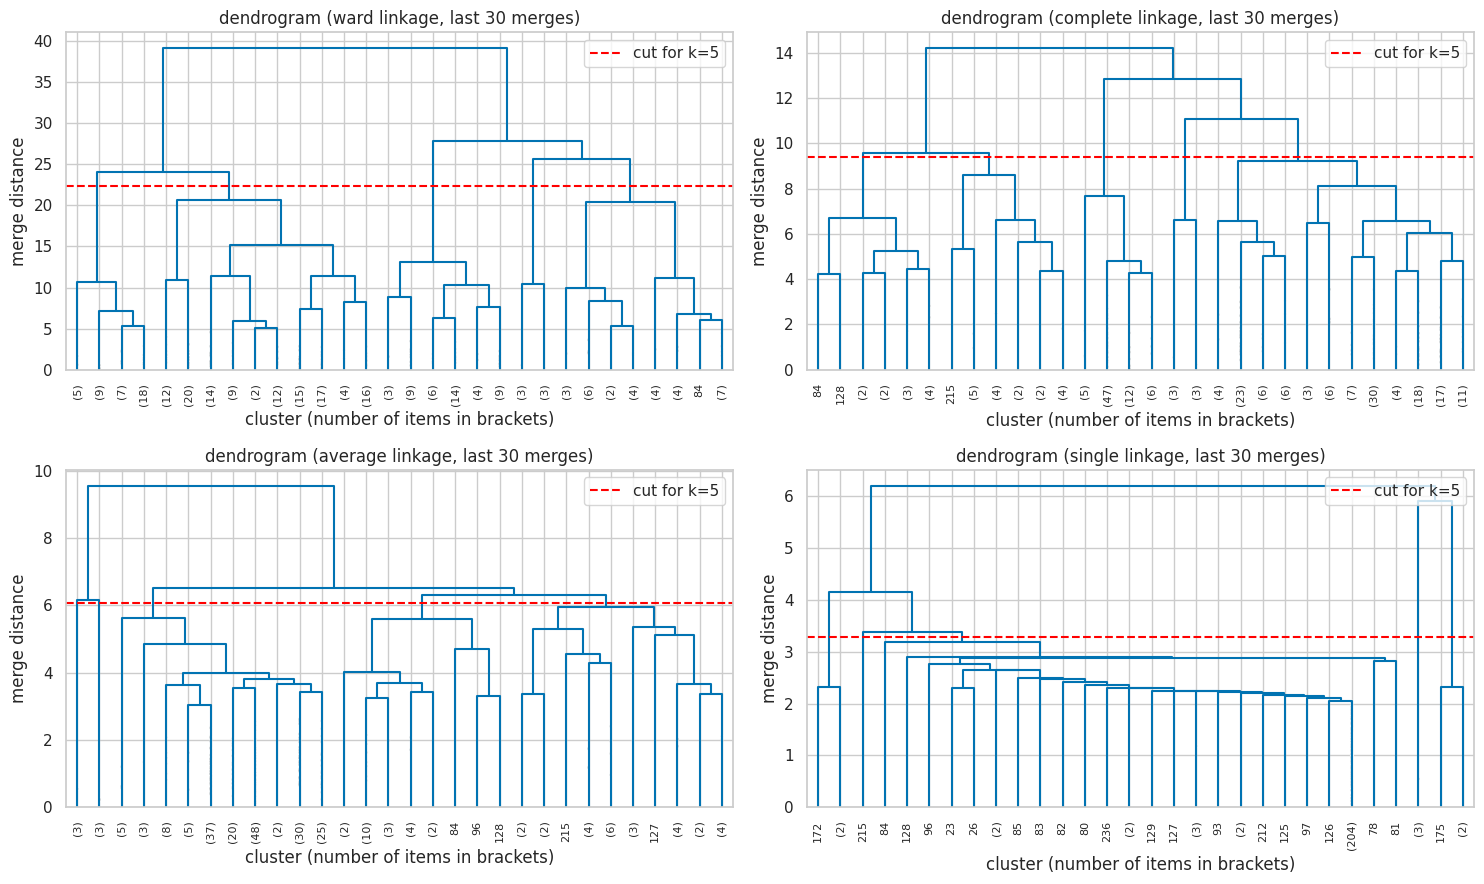

In [14]:
linkages = ["ward", "complete", "average", "single"]
Z = {m: linkage(X_scaled, method=m) for m in linkages}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, m in zip(axes.ravel(), linkages):
    dendrogram(Z[m], truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8,
               show_contracted=True, color_threshold=0, above_threshold_color=PALETTE[0], ax=ax)
    cut = (Z[m][-K_CHOSEN, 2] + Z[m][-(K_CHOSEN - 1), 2]) / 2
    ax.axhline(cut, color="red", ls="--", label=f"cut for k={K_CHOSEN}")
    ax.set_title(f"dendrogram ({m} linkage, last 30 merges)")
    ax.set_xlabel("cluster (number of items in brackets)")
    ax.set_ylabel("merge distance")
    ax.legend()
plt.tight_layout()
plt.show()

**observation:** *(write your own: how the linkages differ, e.g. single linkage chaining vs ward's compact clusters)*

### 6.2 comparing linkage strategies

Single and average linkage can score a high silhouette just by isolating a few outliers into tiny clusters. To avoid that, a linkage is only eligible for selection if its smallest cluster has at least 3 items (or 2% of the data).

In [15]:
min_size = max(3, int(0.02 * len(X_scaled)))
link_rows = []
for m in linkages:
    lab = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=m).fit_predict(X_scaled)
    coph, _ = cophenet(Z[m], pdist(X_scaled))
    link_rows.append({"Linkage": m, **cluster_metrics(X_scaled, lab),
                      "Cophenetic corr": coph, "Min cluster size": np.bincount(lab).min()})
link_table = pd.DataFrame(link_rows).set_index("Linkage")
display(link_table.round(3))

eligible = link_table[link_table["Min cluster size"] >= min_size]
HIER_LINKAGE = eligible["Silhouette"].idxmax() if len(eligible) else "ward"
# HIER_LINKAGE = "ward"   # uncomment to force a specific linkage
print("linkage used:", HIER_LINKAGE)

agg = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=HIER_LINKAGE).fit(X_scaled)
agg_labels = agg.labels_
print("Agglomerative cluster sizes:", {int(k): int(v) for k, v in pd.Series(agg_labels).value_counts().sort_index().items()})

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cophenetic corr,Min cluster size
Linkage,,,,,
ward,0.181,1.371,56.207,0.537,6
complete,0.143,1.437,49.927,0.506,6
average,0.361,1.041,47.987,0.795,3
single,0.289,0.604,11.945,0.687,1


linkage used: ward
Agglomerative cluster sizes: {0: 121, 1: 31, 2: 45, 3: 6, 4: 39}


## 7. evaluation: all algorithms, all metrics

Silhouette and Calinski-Harabasz: higher is better. Davies-Bouldin: lower is better.

In [16]:
results = {"K-Means": km_labels, f"Agglomerative ({HIER_LINKAGE})": agg_labels}

eval_rows = []
for name, lab in results.items():
    row = {"Algorithm": name, "Clusters": len(set(lab)), **cluster_metrics(X_scaled, lab),
           "Cluster sizes": str(np.bincount(lab).tolist())}
    # ground truth is used here only AFTER fitting, to sanity-check the clusters
    if LABEL_COL:
        truth = df[LABEL_COL].astype(str)
        row["ARI vs category"] = adjusted_rand_score(truth, lab)
        row["NMI vs category"] = normalized_mutual_info_score(truth, lab)
    eval_rows.append(row)

eval_df = pd.DataFrame(eval_rows).set_index("Algorithm")
display(eval_df.round(4))

,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes,ARI vs category,NMI vs category
Algorithm,,,,,,,
K-Means,5,0.2846,1.2741,70.5011,"[120, 43, 6, 31, 42]",0.1186,0.3093
Agglomerative (ward),5,0.1809,1.3713,56.2067,"[121, 31, 45, 6, 39]",0.2120,0.4020


**interpretation of the metrics:** *(write your own: which algorithm wins on which metric, whether they agree, what the external ARI/NMI scores say)*

## 8. cluster visualisation

### 8.1 PCA 2D scatter (every algorithm)

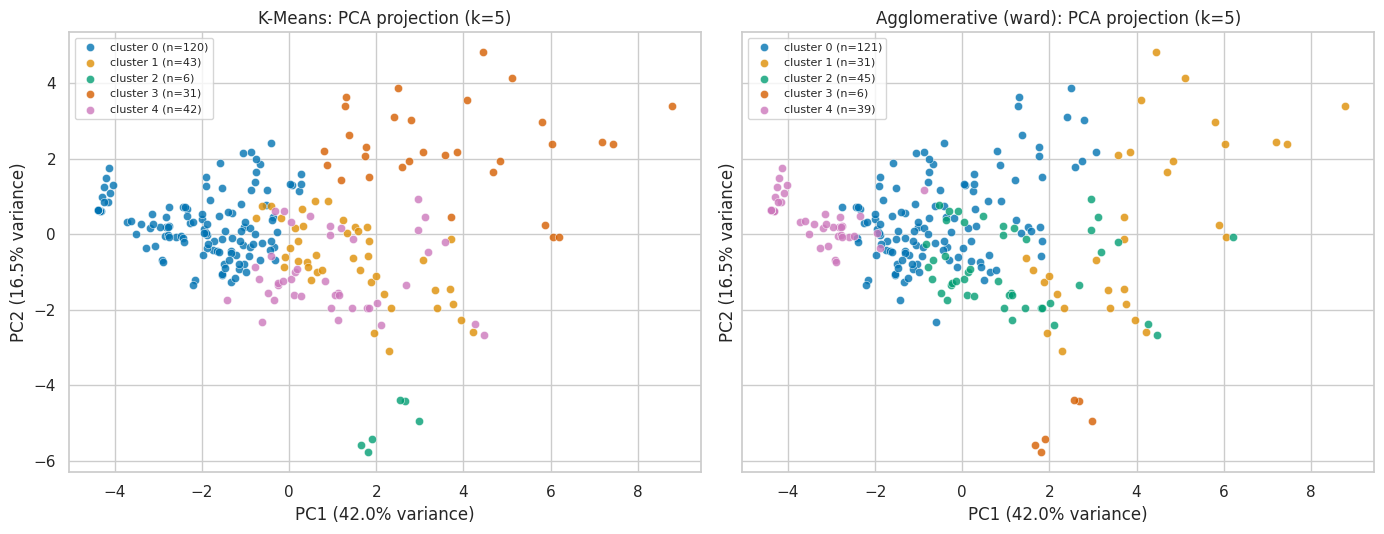

In [17]:
def plot_clusters(ax, coords, labels, title, xlabel, ylabel):
    for c in sorted(set(labels)):
        m = labels == c
        ax.scatter(coords[m, 0], coords[m, 1], s=35, alpha=0.8, color=PALETTE[c % len(PALETTE)],
                   edgecolor="white", linewidth=0.4, label=f"cluster {c} (n={m.sum()})")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 5.5), sharex=True, sharey=True)
for ax, (name, lab) in zip(np.atleast_1d(axes), results.items()):
    plot_clusters(ax, X_pca, lab, f"{name}: PCA projection (k={K_CHOSEN})",
                  f"PC1 ({evr[0]:.1%} variance)", f"PC2 ({evr[1]:.1%} variance)")
plt.tight_layout()
plt.show()

### 8.2 t-SNE (both algorithms)

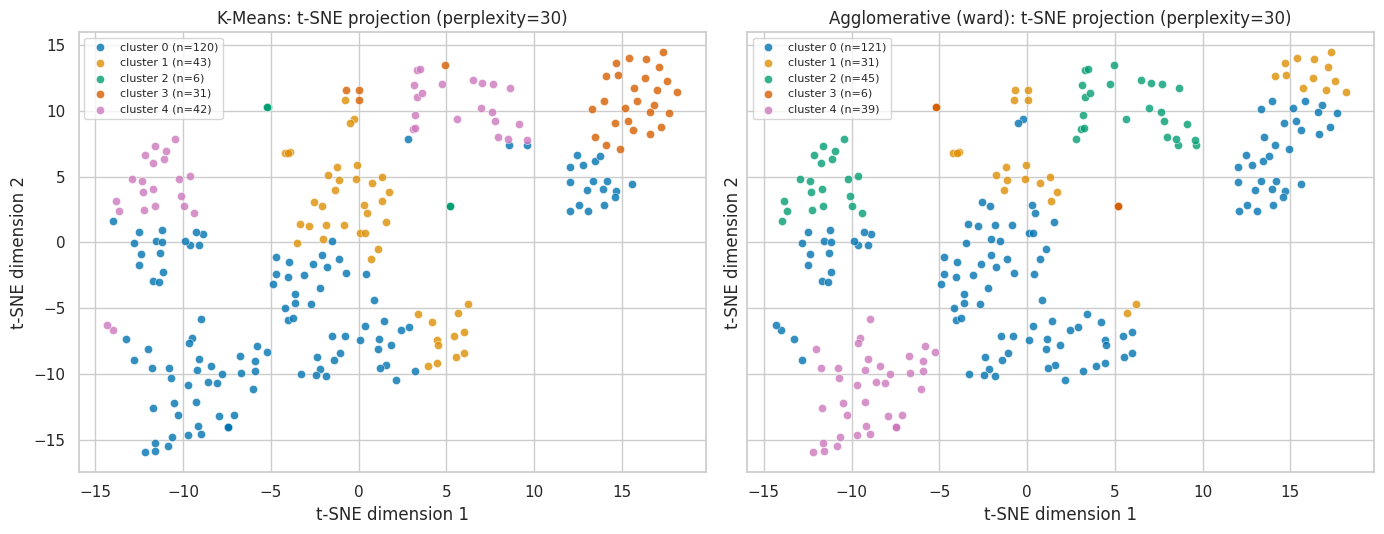

In [18]:
perplexity = min(30, max(5, (len(X_scaled) - 1) // 3))
X_tsne = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=SEED).fit_transform(X_scaled)

fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 5.5), sharex=True, sharey=True)
for ax, (name, lab) in zip(np.atleast_1d(axes), results.items()):
    plot_clusters(ax, X_tsne, lab, f"{name}: t-SNE projection (perplexity={perplexity})",
                  "t-SNE dimension 1", "t-SNE dimension 2")
plt.tight_layout()
plt.show()

**observation:** *(write your own: how well separated the clusters look, where they overlap, any differences between PCA and t-SNE)*

## 9. cluster profiling (what does each cluster mean?)

Mean feature values per cluster in original units, and a standardised heatmap showing which features are above or below average for each cluster.

--- K-Means: mean feature values per cluster ---


,n_items,calories,total_fat,trans_fat,saturated_fat,sodium,total_carbohydrates,cholesterol,dietary_fibre,sugars,protein,vitamin_a,vitamin_c,calcium,iron,caffeine
cluster,,,,,,,,,,,,,,,,
0,120,115.1,1.4,0.0,0.5,73.9,21.8,3.3,0.3,20.5,4.1,6.1,0.6,13.4,3.0,82.2
1,43,239.5,3.9,0.0,1.2,144.1,40.5,4.1,1.8,34.6,12.5,16.3,3.3,38.3,16.5,104.9
2,6,278.3,1.5,0.0,0.5,122.5,55.7,5.0,6.7,38.7,15.8,26.7,90.0,10.0,11.0,2.5
3,31,294.5,7.8,0.2,4.4,182.1,45.9,24.0,0.5,42.6,12.3,17.2,2.7,37.7,7.4,109.0
4,42,285.7,2.8,0.0,1.6,232.0,61.8,4.6,0.7,59.0,4.4,6.0,1.0,13.0,10.2,84.8


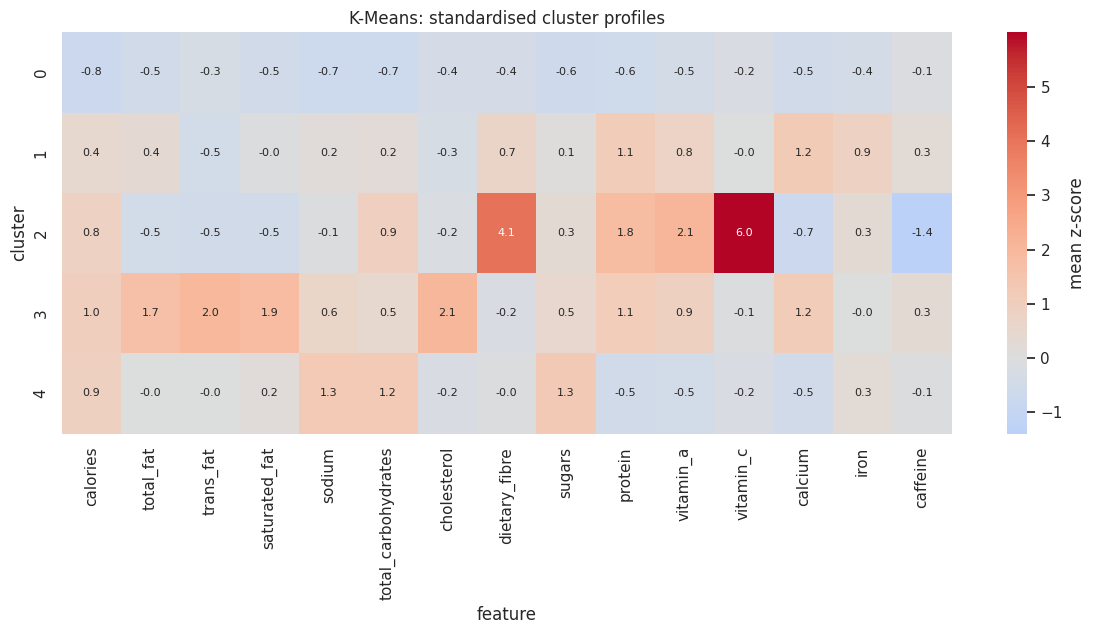

--- Agglomerative (ward): mean feature values per cluster ---


,n_items,calories,total_fat,trans_fat,saturated_fat,sodium,total_carbohydrates,cholesterol,dietary_fibre,sugars,protein,vitamin_a,vitamin_c,calcium,iron,caffeine
cluster,,,,,,,,,,,,,,,,
0,121,164.5,2.6,0.0,1.0,108.6,28.5,6.5,0.5,26.3,7.1,10.8,0.7,23.6,5.4,76.0
1,31,328.1,7.2,0.1,3.6,187.3,54.4,15.2,2.1,47.3,15.3,18.5,5.8,43.9,17.9,107.4
2,45,277.8,3.1,0.0,1.8,239.6,59.2,5.2,0.8,56.6,4.6,6.1,1.1,13.4,10.9,88.1
3,6,278.3,1.5,0.0,0.5,122.5,55.7,5.0,6.7,38.7,15.8,26.7,90.0,10.0,11.0,2.5
4,39,68.6,0.4,0.0,0.1,18.6,14.8,0.5,0.0,14.2,1.4,1.7,0.6,3.8,0.9,123.7


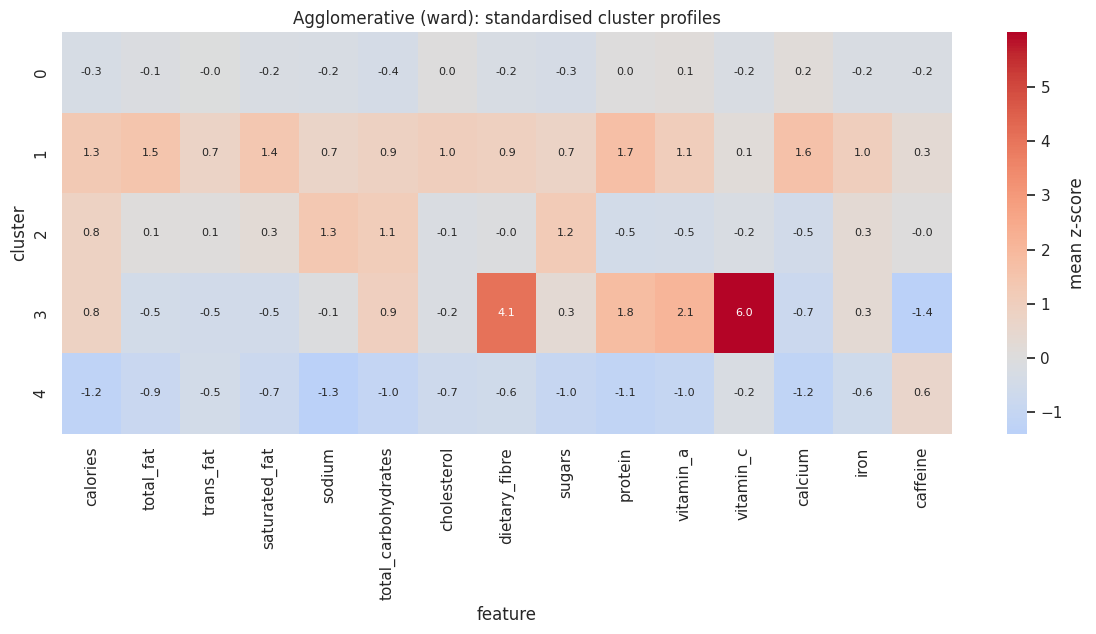

In [19]:
def profile(labels, name):
    prof = df[numeric_cols].groupby(labels).mean().round(1)
    prof.insert(0, "n_items", pd.Series(labels).value_counts().sort_index().values)
    prof.index.name = "cluster"
    print(f"--- {name}: mean feature values per cluster ---")
    display(prof)

    z = pd.DataFrame(X_scaled, columns=numeric_cols).groupby(labels).mean()
    plt.figure(figsize=(12, 0.9 * len(z) + 2))
    sns.heatmap(z, annot=True, fmt=".1f", cmap="coolwarm", center=0, annot_kws={"size": 8},
                cbar_kws={"label": "mean z-score"})
    plt.title(f"{name}: standardised cluster profiles")
    plt.xlabel("feature")
    plt.ylabel("cluster")
    plt.tight_layout()
    plt.show()

for name, lab in results.items():
    profile(lab, name)

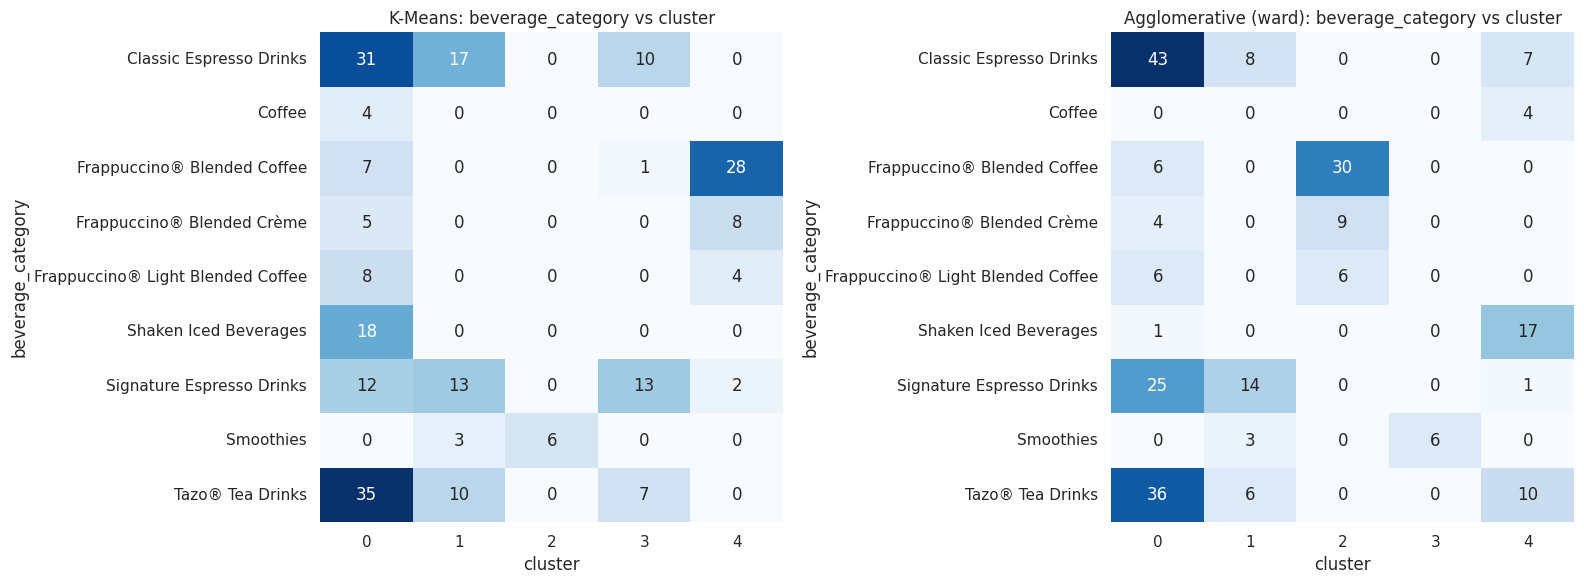

In [20]:
# post-hoc: how do the clusters line up with the menu's own categories?
if LABEL_COL:
    fig, axes = plt.subplots(1, len(results), figsize=(8 * len(results), 6))
    for ax, (name, lab) in zip(np.atleast_1d(axes), results.items()):
        ct = pd.crosstab(df[LABEL_COL], pd.Series(lab, name="cluster"))
        sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_title(f"{name}: {LABEL_COL} vs cluster")
        ax.set_xlabel("cluster")
        ax.set_ylabel(LABEL_COL)
    plt.tight_layout()
    plt.show()

**cluster names and meaning:** *(write your own: give each K-Means cluster a short name such as "low-calorie teas", "high-sugar blended drinks", and justify it from the profile table)*

## 10. conclusion

*(Write in your own words.)*
- which algorithm gave the better clustering and on what evidence (metrics, plots, interpretability)
- how many natural groups the menu has and what separates them
- trade-offs: K-Means (fast, needs k, spherical clusters) vs hierarchical (no k needed up front, dendrogram, O(n^2) memory)
- limitations (correlated features, skew, serving-size variants, only nutrition columns used) and what you would try next (e.g. log transform, DBSCAN, Gaussian mixture)